In [1]:
import numpy as np
import pickle

with open("data/data_variant.pickle", "rb") as p:
    data = pickle.load(p)

train_x = []
test_x = []
train_y = np.array(data["train"][1]) - 1
test_y = np.array(data["test"][1]) - 1

for i in data["train"][0]:
    train_x.append(np.array(i).T.tolist())
for i in data["test"][0]:
    test_x.append(np.array(i).T.tolist())

In [2]:
import pandas as pd

def to_nested_dataframe(recordings, channel_names=None):
    """Convert arrays of shape (timepoints, channels) to an sktime panel."""
    if len(recordings) == 0:
        raise ValueError("At least one recording is required.")

    arrays = [np.asarray(recording, dtype=np.float64)
              for recording in recordings]

    if any(array.ndim != 2 for array in arrays):
        raise ValueError(
            "Each recording must have shape (n_timepoints, n_channels)."
        )

    n_channels = arrays[0].shape[1]
    if n_channels == 0:
        raise ValueError("Recordings must contain at least one channel.")

    for i, array in enumerate(arrays):
        if array.shape[1] != n_channels:
            raise ValueError(f"Recording {i} has a different channel count.")
        if array.shape[0] < 2:
            raise ValueError(
                f"Recording {i} needs at least two points for interpolation."
            )
        if not np.isfinite(array).all():
            raise ValueError(
                f"Recording {i} contains NaN or infinite values; "
                "handle these before using this template."
            )

    if channel_names is None:
        channel_names = [f"channel_{j}" for j in range(n_channels)]
    else:
        channel_names = list(channel_names)

    if len(channel_names) != n_channels:
        raise ValueError("channel_names must match the number of channels.")
    if len(set(channel_names)) != n_channels:
        raise ValueError("Channel names must be unique.")

    return pd.DataFrame({
        name: [pd.Series(array[:, j]) for array in arrays]
        for j, name in enumerate(channel_names)
    })

channels = ["bvp", "resp"]

train_x = to_nested_dataframe(train_x, channel_names=channels)
test_x = to_nested_dataframe(test_x, channel_names=channels)

In [3]:
from sklearn.metrics import accuracy_score, classification_report
from sktime.classification.interval_based import DrCIF
from sktime.classification.dictionary_based import ContractableBOSS
from sktime.classification.feature_based import TSFreshClassifier
from sktime.transformations.interpolate import TSInterpolator

interpolate = TSInterpolator(length=200)

X_train_features = interpolate.fit_transform(train_x)
X_test_features = interpolate.transform(test_x)

cls = TSFreshClassifier(n_jobs=-1)

cls.fit(X_train_features, train_y)

y_pred = cls.predict(X_test_features)

print(f"Accuracy: {accuracy_score(test_y, y_pred):.3f}")
print(classification_report(test_y, y_pred, zero_division=0))

Accuracy: 0.833
              precision    recall  f1-score   support

           0       1.00      0.60      0.75         5
           1       1.00      1.00      1.00         5
           2       0.71      1.00      0.83         5
           3       1.00      0.40      0.57         5
           4       0.71      1.00      0.83         5
           5       0.83      1.00      0.91         5

    accuracy                           0.83        30
   macro avg       0.88      0.83      0.82        30
weighted avg       0.88      0.83      0.82        30



In [4]:
cls.save("final_model_release/tsfresh")

<zipfile.ZipFile filename='final_model_release/tsfresh.zip' mode='r'>

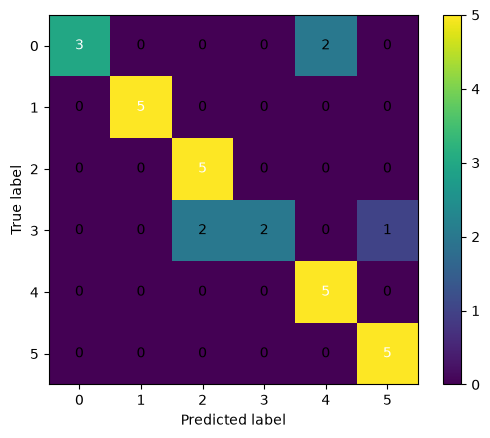

In [5]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(test_y, y_pred)
plt.imshow(cm)
plt.colorbar()
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [3]:
box_train_data_idx = [i for i, _ in enumerate(data["train"][1]) if _ in [1, 3, 4]]
inhaler_train_data_idx = [i for i, _ in enumerate(data["train"][1]) if _ in [2, 5, 6]]
box_test_data_idx = [i for i, _ in enumerate(data["test"][1]) if _ in [1, 3, 4]]
inhaler_test_data_idx = [i for i, _ in enumerate(data["test"][1]) if _ in [2, 5, 6]]

In [4]:
box_test_data_idx

[0, 1, 2, 3, 4, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]

In [5]:
inhaler_test_data_idx

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 25, 26, 27, 28, 29]

In [4]:
box_train_x = []
box_train_y = []
box_test_x = []
box_test_y = []

for i in box_train_data_idx:
    box_train_x.append(np.array(data["train"][0][i]).T.tolist())
    box_train_y.append(data["train"][1][i] - 1)

for i in box_test_data_idx:
    box_test_x.append(np.array(data["test"][0][i]).T.tolist())
    box_test_y.append(data["test"][1][i] - 1)

In [13]:
box_train_y

[3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2]

In [7]:
box_train_x

[[[0.009075937532487088, -0.009593039697501178],
  [0.2622119240114515, -0.009479703957428472],
  [0.48218563326280156, -0.009360948284042917],
  [0.6262665286181831, -0.009237415170679417],
  [0.6496919902036766, -0.009109780293210495],
  [0.528957789765899, -0.008978858237092218],
  [0.28396384701253985, -0.008845681169669665],
  [-0.019420365426765923, -0.00871153877791336],
  [-0.2908641314690688, -0.008577987523687589],
  [-0.450754192255568, -0.008446847155722657],
  [-0.46240733050363275, -0.008320187971201317],
  [-0.3456372770702906, -0.008200287922555973],
  [-0.1633095685220692, -0.00808953831951416],
  [0.012798747083317269, -0.007990305441917311],
  [0.1365946038526752, -0.007904779881436414],
  [0.20217711933683094, -0.007834843169031512],
  [0.23221411264403494, -0.0077819593307865325],
  [0.2513210090503023, -0.007747075807407995],
  [0.2640387670400712, -0.007730512059601801],
  [0.2523774507902101, -0.007731835839347397],
  [0.19222446868306758, -0.007749763928898987]

In [5]:
channels = ["bvp", "resp"]

box_train_x = to_nested_dataframe(box_train_x, channel_names=channels)
box_test_x = to_nested_dataframe(box_test_x, channel_names=channels)
box_train_y = np.array(box_train_y)
box_test_y = np.array(box_test_y)

In [6]:
inhaler_train_x = []
inhaler_train_y = []
inhaler_test_x = []
inhaler_test_y = []

for i in inhaler_train_data_idx:
    inhaler_train_x.append(np.array(data["train"][0][i]).T.tolist())
    inhaler_train_y.append(data["train"][1][i] - 1)

for i in inhaler_test_data_idx:
    inhaler_test_x.append(np.array(data["test"][0][i]).T.tolist())
    inhaler_test_y.append(data["test"][1][i] - 1)

In [7]:
inhaler_train_x = to_nested_dataframe(inhaler_train_x, channel_names=channels)
inhaler_test_x = to_nested_dataframe(inhaler_test_x, channel_names=channels)
inhaler_train_y = np.array(inhaler_train_y)
inhaler_test_y = np.array(inhaler_test_y)

In [9]:
from sklearn.metrics import accuracy_score, classification_report
from sktime.classification.feature_based import TSFreshClassifier
from sktime.transformations.interpolate import TSInterpolator

interpolate = TSInterpolator(length=200)

X_train_features = interpolate.fit_transform(box_train_x)
X_test_features = interpolate.transform(box_test_x)

cls = TSFreshClassifier(n_jobs=-1)

cls.fit(X_train_features, box_train_y)

y_pred = cls.predict(X_test_features)

print(f"Accuracy: {accuracy_score(box_test_y, y_pred):.3f}")
print(classification_report(box_test_y, y_pred, zero_division=0))

Accuracy: 0.867
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           2       0.71      1.00      0.83         5
           3       1.00      0.60      0.75         5

    accuracy                           0.87        15
   macro avg       0.90      0.87      0.86        15
weighted avg       0.90      0.87      0.86        15



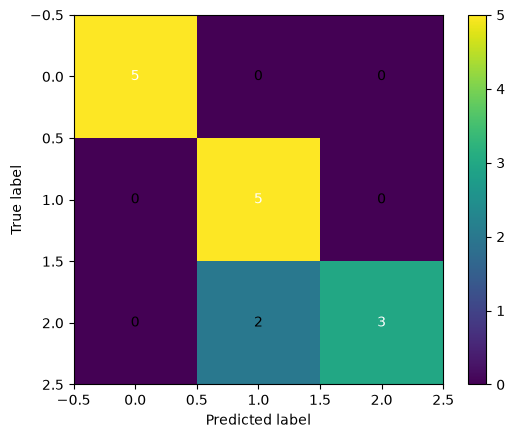

In [10]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(box_test_y, y_pred)
plt.imshow(cm)
plt.colorbar()
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [11]:
cls.save("final_model_release/box")

<zipfile.ZipFile filename='final_model_release/box.zip' mode='r'>

In [12]:
X_train_features = interpolate.fit_transform(inhaler_train_x)
X_test_features = interpolate.transform(inhaler_test_x)

cls = TSFreshClassifier(n_jobs=-1)

cls.fit(X_train_features, inhaler_train_y)

y_pred = cls.predict(X_test_features)

print(f"Accuracy: {accuracy_score(inhaler_test_y, y_pred):.3f}")
print(classification_report(inhaler_test_y, y_pred, zero_division=0))

Accuracy: 1.000
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         5
           4       1.00      1.00      1.00         5
           5       1.00      1.00      1.00         5

    accuracy                           1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15



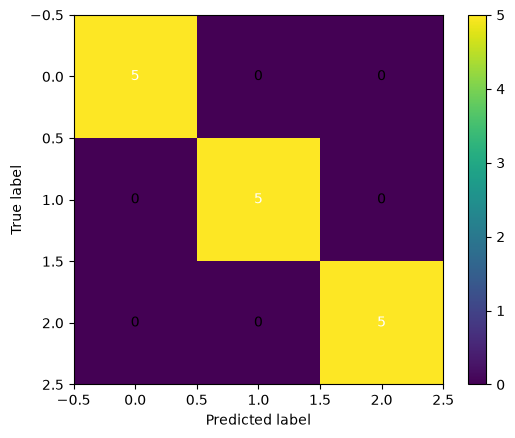

In [13]:
cm = confusion_matrix(inhaler_test_y, y_pred)
plt.imshow(cm)
plt.colorbar()
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [14]:
cls.save("final_model_release/inhaler")

<zipfile.ZipFile filename='final_model_release/inhaler.zip' mode='r'>